In [1]:
# Add the root path of the pyqula library
import os ; import sys
try: sys.path.append(os.environ["PYQULAROOT"]) # add the library via environmental variable
except: pass
try: from pyqula import geometry # check if the library is present
except: # pyqula not installed
    print("pyqula needs to be installed, installing it")
    import subprocess ; subprocess.check_call([sys.executable, "-m", "pip", "install", "--upgrade","pyqula"])

# some default parameters in matplotlib
import matplotlib.pyplot as plt
plt.rcParams['figure.figsize'] = [20, 8]
plt.rcParams['font.size'] = 22
plt.rcParams['image.cmap'] = 'coolwarm'


import numpy as np

# Advanced Quantum Materials, session 4: The Quantum Hall effect
In this session we will address the quantum Hall effect, including Landau levels and the emergence of topological edge states for both quadratic and Dirac electrons

### Contents
- Landau levels the quantum Hall state for quadratic electrons
- Edge states in the quantum Hall state for quadratic electrons
- Energy spacing between Landau levels for quadratic electrons
- Landau levels the quantum Hall state for Dirac electrons
- Edge states in the quantum Hall state for Dirac electrons
- Energy spacing between Landau levels for Dirac electrons

### Learning outcomes
- Identify Landau levels in an electronic spectra
- Understanding the energy scaling with the magnetic field

### About the exercises
The notebooks contain three types of exercises, with each exercise containing **Quiz** questions to answer
- ***Reminder***: brief recall from previous sessions, you can skip it if you remember it
- ***Core***: basic exercises you should understand in each session
- ***Challenge***: advanced exercises to dive deeper into concepts, not necessary to understand in full in each session

## The dispersion of the square lattice (***Reminder***)
This is a reminder of the dispersion in the square lattice

The square lattice with first neighbor hopping has the dispersion $E(\mathbf k)=-2t(\cos k_x+\cos k_y)$. Close to the bottom of the band, around $\Gamma=(0,0)$, you can expand it as $E(\mathbf k)\approx -4t+t\,|\mathbf k|^2$, meaning that there the electrons behave as free electrons with a quadratic dispersion. This is only true close to the band edges, not in the whole Brillouin zone.

(0.0, 399.0)

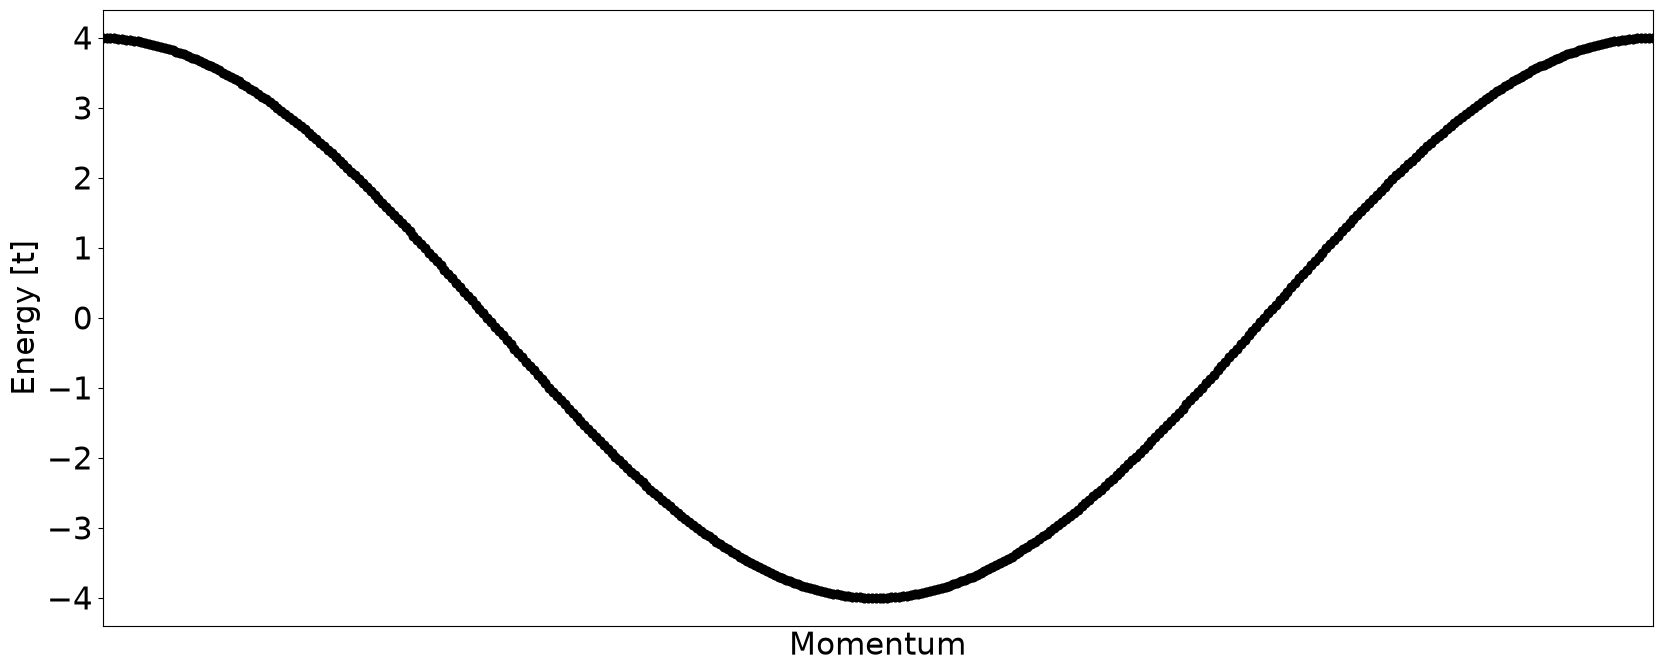

In [2]:
from pyqula import geometry
g = geometry.square_lattice() # geometry of the square lattice
h = g.get_hamiltonian() # generate the Hamiltonian
(k,e) = h.get_bands() # compute band structure
plt.scatter(k,e,c="black") ; plt.xlabel("Momentum") ; plt.ylabel("Energy [t]") 
plt.xticks([]) ; plt.xlim([min(k),max(k)])

### Quiz
- At which energies do you have a dispersion relation $E \sim k^2$?
- Replace the square lattice by a triangular one (triangular_lattice). At which energies the dispersion is quadratic?

## Bands in the conventional quantum Hall state (***Reminder***)
Let us review the bandstructure in the quantum Hall state

This is the same construction as in session 3, a ribbon with a magnetic field added through the Peierls substitution, but now for the square lattice. The point of starting here is that close to the bottom of the band the electrons are quadratic, and this is the situation in which conventional Landau levels appear, which is what we look at next.

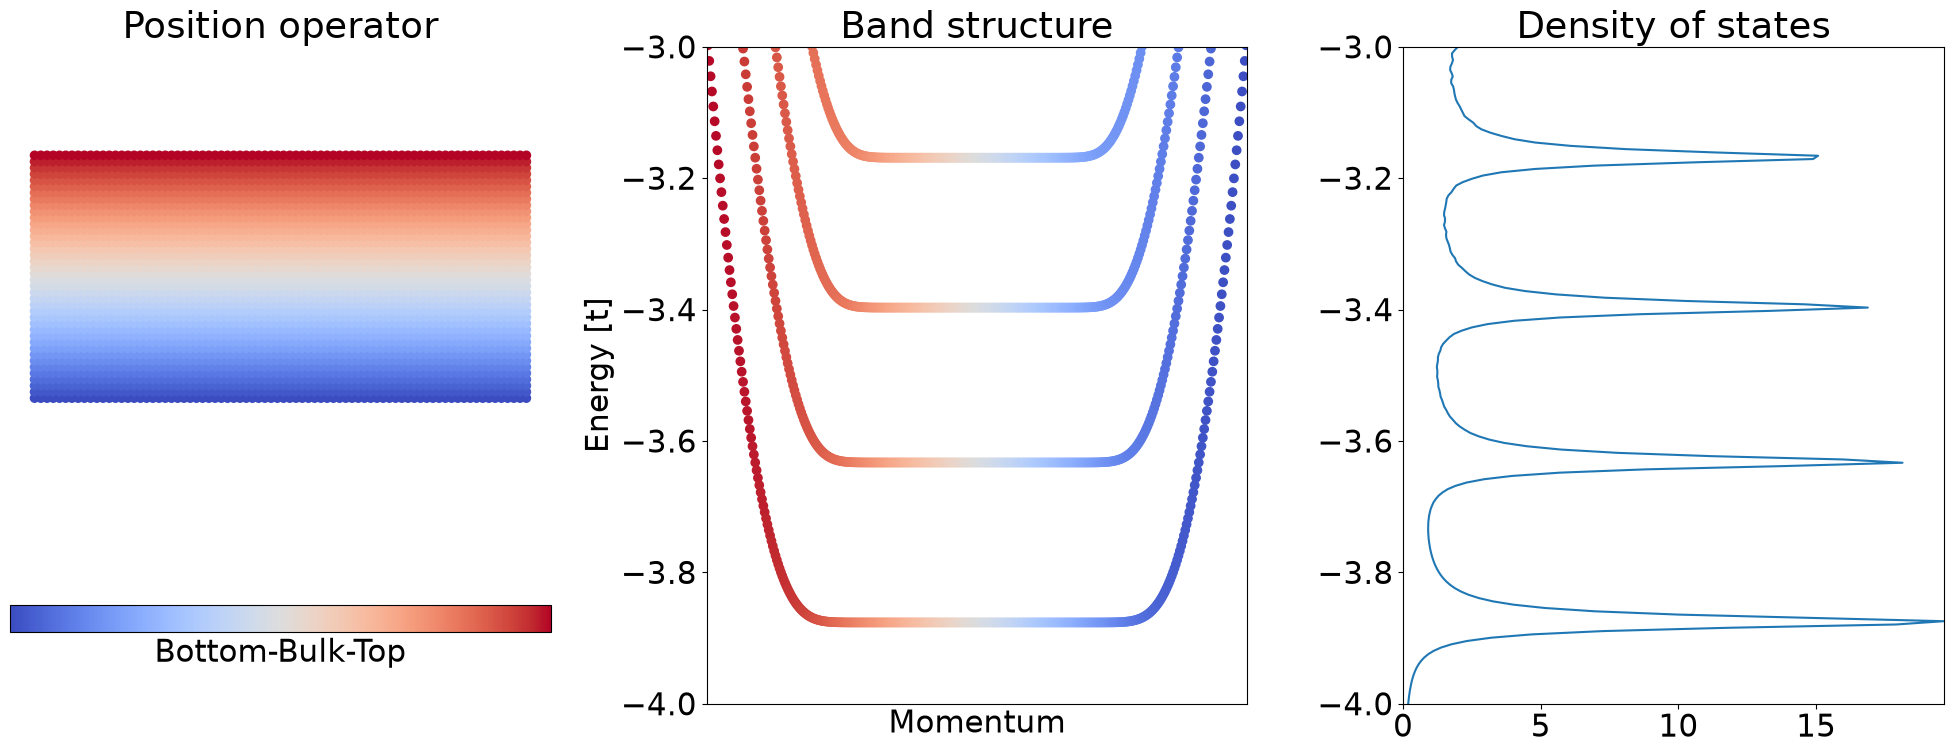

In [3]:
from pyqula import geometry
W = 40 # width
g = geometry.square_ribbon(W) # square ribbon, the number controls the width
h = g.get_hamiltonian(has_spin=False) # generate the Hamiltonian
B = 0.02 # magnetic field (in unit flux units)
h.add_orbital_magnetic_field(B) # add an out-of plane magnetic field

# draw a ribbon with the position operator
gs = g.get_supercell(2*W) 
plt.subplot(1,3,1) ; plt.title("Position operator")
plt.scatter(gs.r[:,0],gs.r[:,1],c=gs.r[:,1]) ; plt.axis("equal") ; plt.axis("off")
plt.colorbar(location="bottom",ticks=[],label="Bottom-Bulk-Top")

# plot the bands
plt.subplot(1,3,2) ; plt.title("Band structure")
energies = np.linspace(-4.,-3,200) # energies for the DOS (to be used later)
(k,e,c) = h.get_bands(kpath=["G","X","G"],operator="yposition") # compute band structure
plt.scatter(k,e,c=c) ; plt.xlabel("Momentum") ; plt.ylabel("Energy [t]") ; plt.xticks([]) 
plt.ylim([min(energies),max(energies)]) ; plt.xlim([min(k),max(k)])


# now plot the DOS
plt.subplot(1,3,3) ; plt.title("Density of states")
(e,d) = h.get_dos(energies=energies,delta=1e-2,nk=400) # compute DOS
plt.plot(d,e) ; plt.xlim([0,max(d)]) ; plt.ylim([min(e),max(e)]) # plot the DOS

plt.tight_layout()

### Quiz
- Where are the red, grey and blue states located?
- What are the flat states and the dispersive states?
- Increase the magnetic field $B$, how are the states affected and why?
- Increase the width of the ribbon $W$, how are the states affected and why?

## Landau levels of conventional electrons (***Core***)
We will show how edge states and flat bands appear when including a magnetic field

For electrons with a quadratic dispersion, the magnetic field quantizes the motion into Landau levels
$$E_n = -4t + \hbar\omega_c\left(n+\tfrac12\right),\qquad \omega_c\propto B$$
that are equally spaced in energy, with a spacing that grows linearly with the field. These are the flat bands that you see at the bottom of the spectrum, and the states that disperse in between them are the edge states.

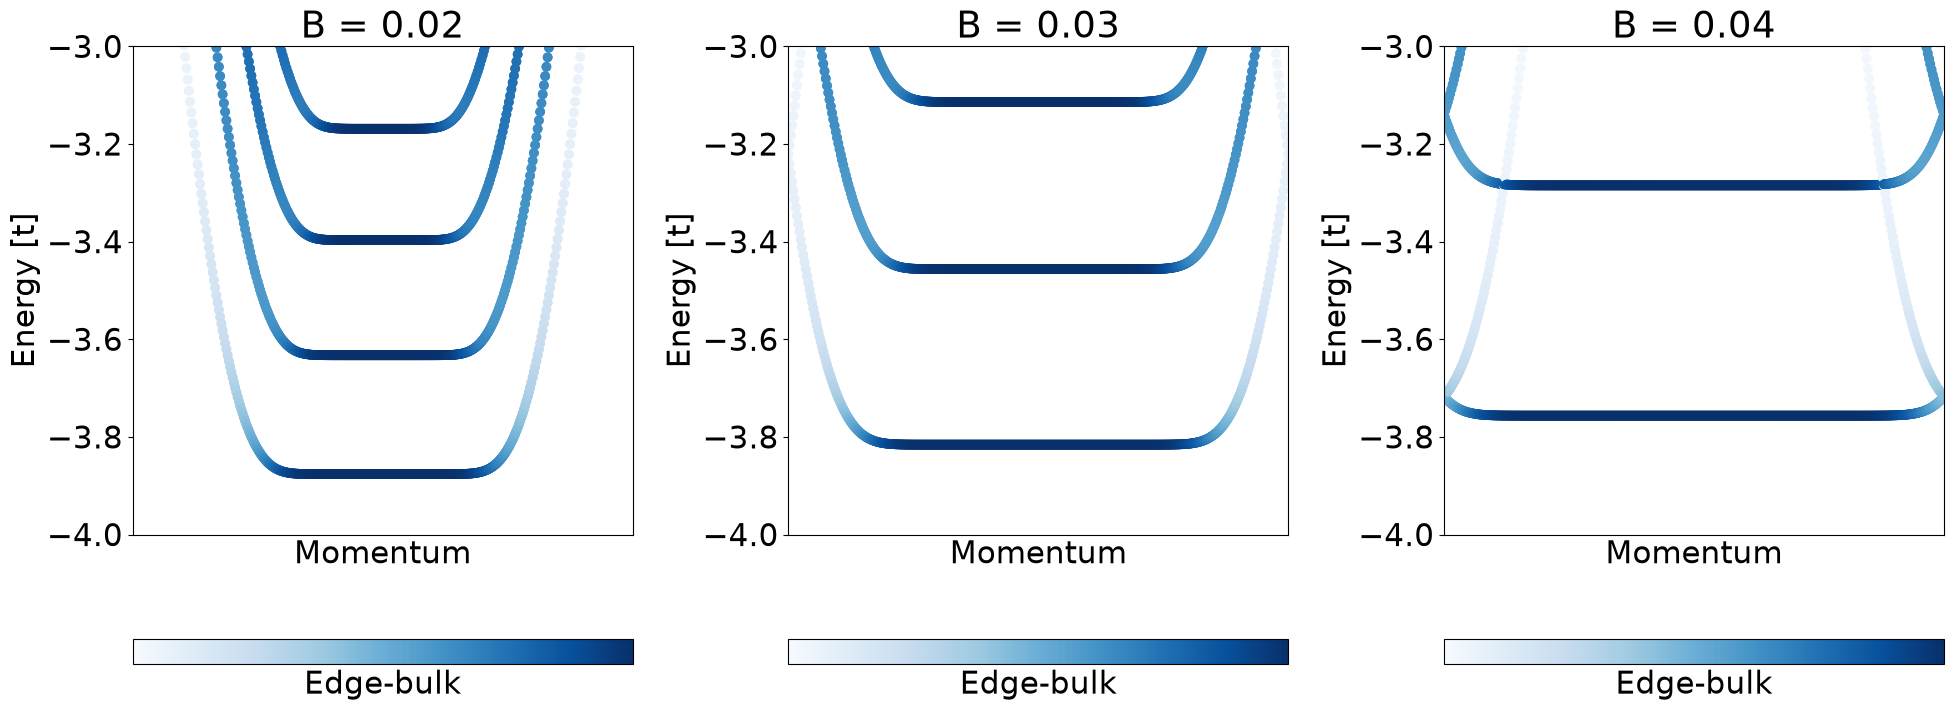

In [4]:
from pyqula import geometry
N = 30 # number of unit cells as the width
g = geometry.square_ribbon(N) # square ribbon, the number controls the width
Bs = [0.02,0.03,0.04] # magnetic field (measured in units of magnetic flux)

ii = 0 # counter
for B in Bs: # loop over magnetic fields
    h = g.get_hamiltonian() # generate the Hamiltonian
    h.add_orbital_magnetic_field(B) # add an out-of plane magnetic field
    # plot the bands
    plt.subplot(1,len(Bs),ii+1) ; plt.title("B = "+str(B)) ; ii += 1 # create subplot and increase counter
    (k,e,c) = h.get_bands(kpath=["G","X","G"],operator="bulk") # compute band structure
    plt.scatter(k,e,c=c,cmap="Blues") ; plt.xlabel("Momentum") ; plt.ylabel("Energy [t]") ; plt.xticks([])
    plt.ylim([-4,-3]) ; plt.xlim([min(k),max(k)])
    plt.colorbar(location="bottom",ticks=[],label="Edge-bulk")
plt.tight_layout()

### Quiz
- Why are there Landau levels of conventional electrons at the bottom of the spectra of a square lattice
- Why does the energy of the lowest Landau level increase with field
- Why does the spacing between Landau levels increase with field
- Increase the width of the ribbon. Do the energies of the flat bands change? Explain why

## Magnetic field dependence of Landau levels (***Core***)
Let us now explicitly see how the energy of the Landau levels depends on the magnetic field

Here we compute the density of states of the ribbon for several magnetic fields. Every Landau level is a flat band, and a flat band gives a very sharp peak in the density of states, that here has a finite width just because of the smearing we use in the calculation. Look at how the position and the separation of the peaks change as you increase $B$.

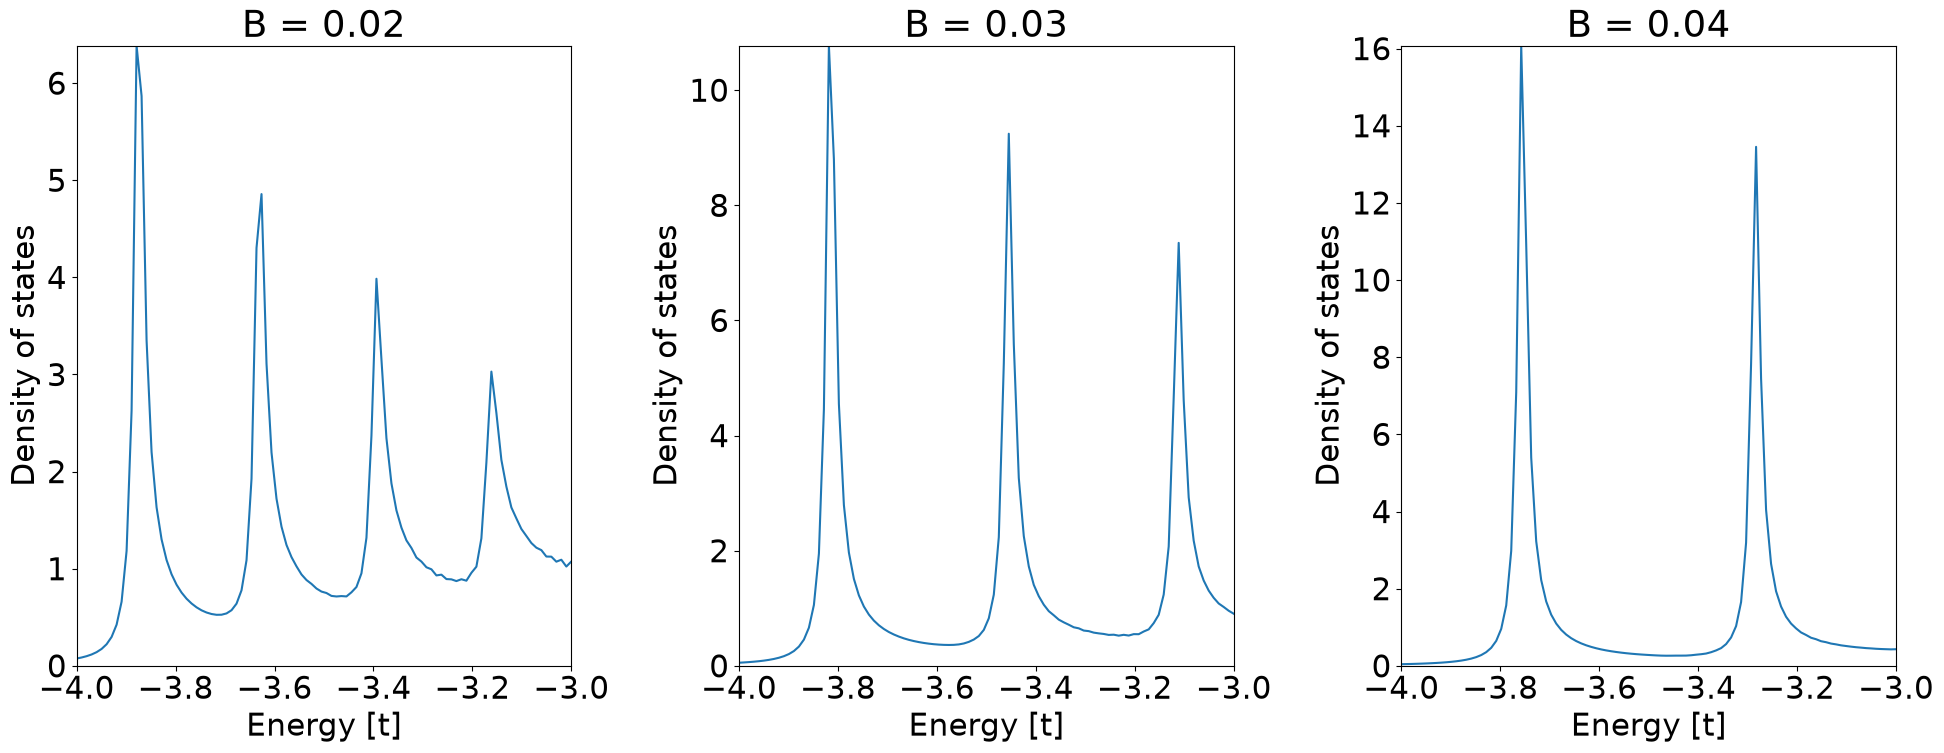

In [5]:
from pyqula import geometry
W = 20 # number of unit cells as the width
g = geometry.square_ribbon(W) # ribbon, the number controls the width
Bs = [0.02,0.03,0.04] # magnetic field (measured in units of magnetic flux)

energies = np.linspace(-4,-3,100)

ii = 0 # counter
for B in Bs: # loop over magnetic fields
    h = g.get_hamiltonian(has_spin=False) # generate the Hamiltonian
    h.add_orbital_magnetic_field(B) # add an out-of plane magnetic field
    plt.subplot(1,len(Bs),ii+1) ; plt.title("B = "+str(B)) ; ii += 1 # create subplot and increase counter
    (e,d) = h.get_dos(operator="bulk",energies=energies,delta=1e-2,nk=400) # compute DOS projected on the bulk
    plt.plot(e,d) ; plt.ylim([0,max(d)]) ; plt.xlim([min(e),max(e)]) # plot the DOS
    plt.xlabel("Energy [t]") ; plt.ylabel("Density of states")
plt.tight_layout()

### Quiz
- Why are there peaks in the density of states? 
- Increase the width $W$ of the ribbon. Do the peaks change? Explain why.

## Imaging the magnetic field dependence in the Landau levels (***Core***)
We will now see explicitly the evolution of the energy levels with magnetic field

Now we plot the density of states as a function of both the energy and the magnetic field, so that you see all the Landau levels at once. Each level $E_n(B) = -4t+\hbar\omega_c(B)(n+\tfrac12)$ traces a line starting at the band edge, with a slope that depends on the index $n$, and this set of lines is what is called a Landau fan. This is precisely what is measured in magnetotransport experiments.

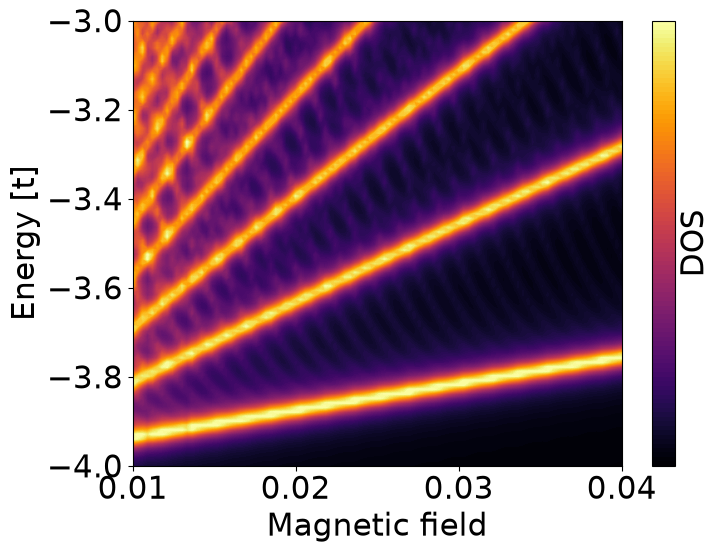

In [6]:
from pyqula import geometry
W = 40 # number of unit cells as the width
g = geometry.square_ribbon(W) # square ribbon 
Bs = np.linspace(0.01,0.04,100) # magnetic field (measured in units of magnetic flux)

energies = np.linspace(-4,-3,100) # energies for the DOS

d_arr,b_arr,e_arr, = [],[],[] # storage for all he energies, magnetic fields and DOS

ii = 0 # counter
for B in Bs: # loop over magnetic fields
    h = g.get_hamiltonian(has_spin=False) # generate the Hamiltonian
    h.add_orbital_magnetic_field(B) # add an out-of plane magnetic field
    (e,d) = h.get_dos(energies=energies,delta=2e-2,nk=40) # compute DOS projected on the bulk
    d_arr.append(d/np.max(d)) ; e_arr.append(e) ; b_arr.append(e*0. + B) # store E, B and DOS

# now make the plot    
fig = plt.figure(figsize=[8,6])
plt.contourf(Bs,energies,np.array(d_arr).T,cmap="inferno",levels=100)
plt.colorbar(label="DOS",ticks=[]) ; plt.xlabel("Magnetic field") ; plt.ylabel("Energy [t]")
plt.xlim([np.min(b_arr),np.max(b_arr)]) ; plt.ylim([np.min(e_arr),np.max(e_arr)])
plt.tight_layout()

### Quiz
- What are the peaks in the DOS?
- Increase the width $W$ of the ribbon. Do the peaks in the DOS change? Explain why.
- How does the spacing between peaks evolve with the magnetic field?
- Make the ribbon much narrower. Why does the density of states become so different?

## The dispersion of the honeycomb lattice (***Reminder***)
This is a reminder of the dispersion in the honeycomb lattice

As we saw in session 2, the honeycomb lattice has two bands $E_\pm(\mathbf k)=\pm|f(\mathbf k)|$, with $f(\mathbf k)=t\sum_i e^{i\mathbf k\cdot\boldsymbol\delta_i}$, and $f$ vanishes linearly at $K$ and $K'$. Close to those points the dispersion is $E(\mathbf q)\approx \pm\hbar v_F|\mathbf q|$, so the electrons are Dirac electrons instead of quadratic ones, and this is going to change the Landau levels.

(0.0, 399.0)

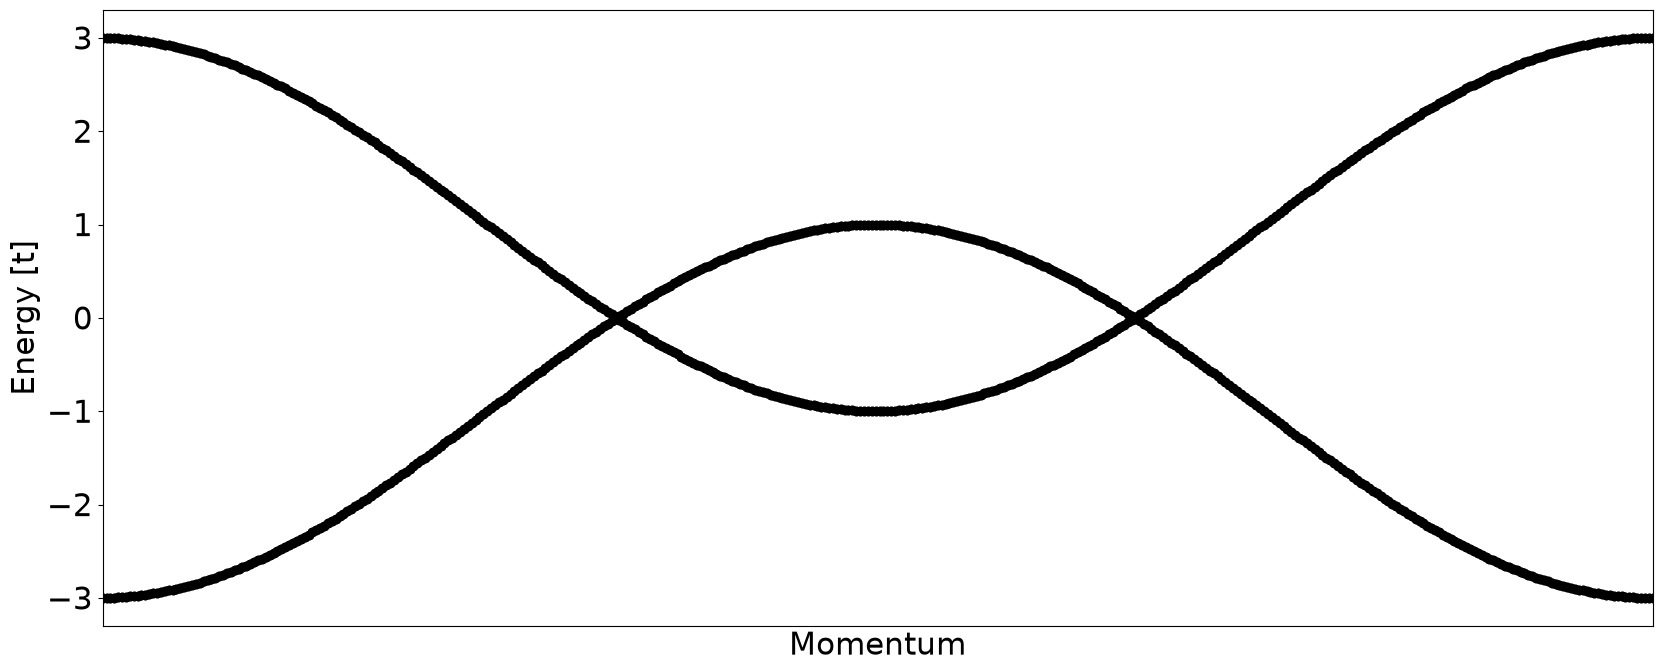

In [7]:
from pyqula import geometry
g = geometry.honeycomb_lattice() # geometry of the honeycomb lattice
h = g.get_hamiltonian() # generate the Hamiltonian
(k,e) = h.get_bands() # compute band structure
plt.scatter(k,e,c="black") ; plt.xlabel("Momentum") ; plt.ylabel("Energy [t]") 
plt.xticks([]) ; plt.xlim([min(k),max(k)])

### Quiz
- At which energies do you have a linear dispersion relation $E \sim |k|$?
- Replace the square lattice by a kagome one (kagome_lattice). At which energies the dispersion is linear?

## Bands in the Dirac quantum Hall state (***Reminder***)
Let us review the bandstructure in the Dirac quantum Hall state

Same construction as before, a ribbon with a magnetic field, but now for the honeycomb lattice. The electrons close to charge neutrality are Dirac electrons, and so the Landau levels that we get are the Landau levels of the Dirac equation, which we look at in detail in the next exercise.

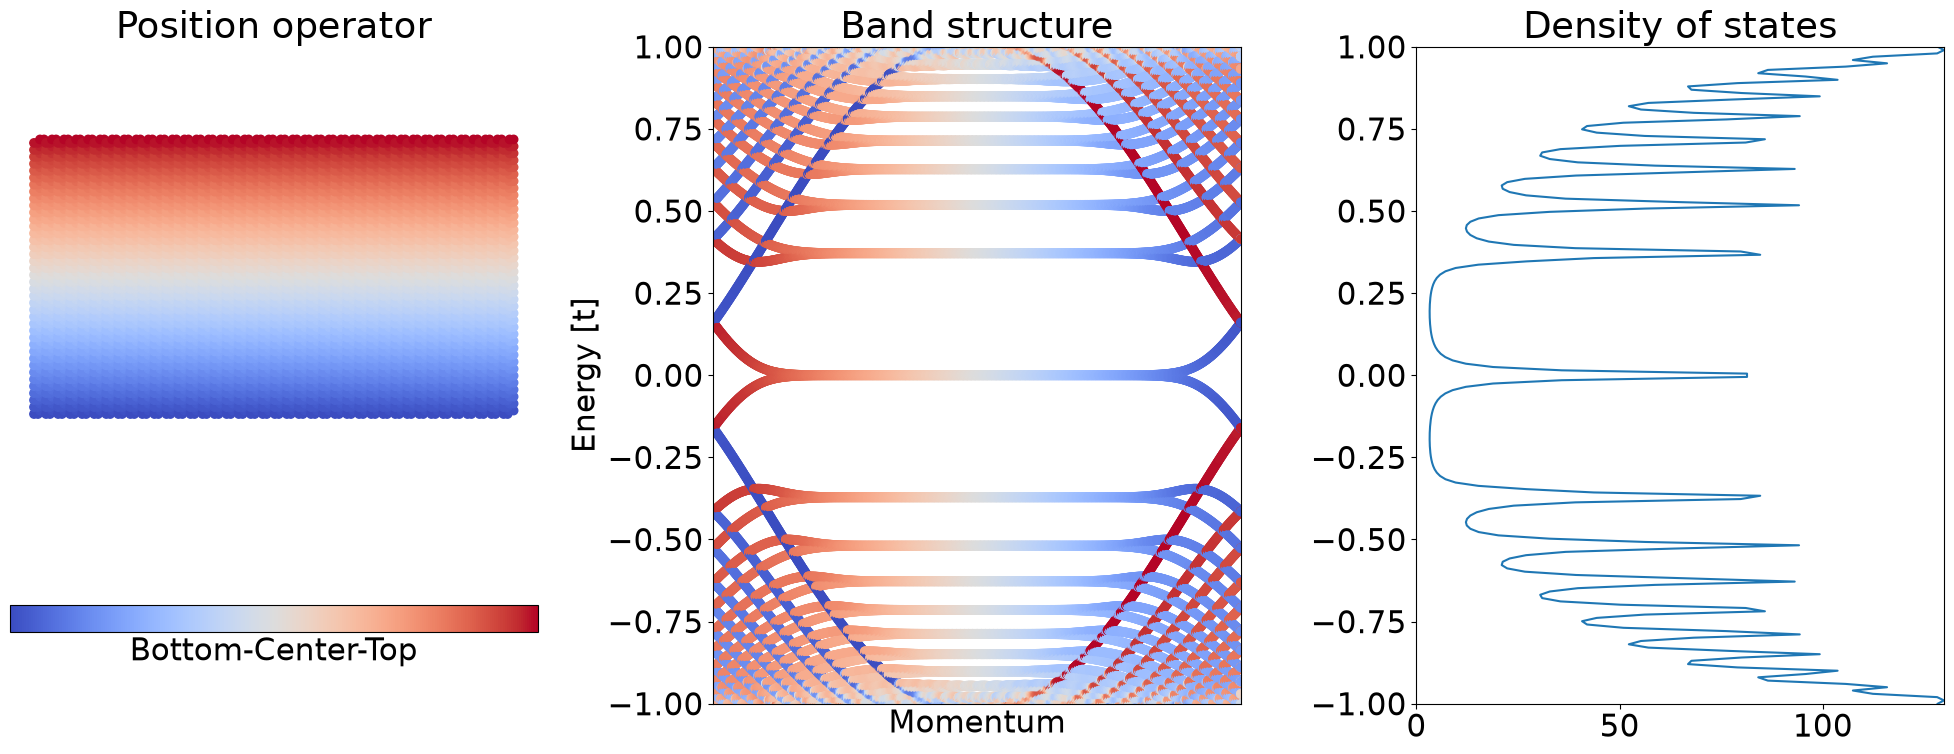

In [8]:
from pyqula import geometry
W = 40 # width
g = geometry.honeycomb_armchair_ribbon(W) # ribbon, the number controls the width
h = g.get_hamiltonian() # generate the Hamiltonian
B = 0.005 # magnetic field (in unit flux units)
h.add_orbital_magnetic_field(B) # add an out-of plane magnetic field

# draw a ribbon with the position operator
gs = g.get_supercell(W) 
plt.subplot(1,3,1) ; plt.title("Position operator")
plt.scatter(gs.r[:,0],gs.r[:,1],c=gs.r[:,1]) ; plt.axis("equal") ; plt.axis("off")
plt.colorbar(location="bottom",ticks=[],label="Bottom-Center-Top")

# plot the bands
plt.subplot(1,3,2) ; plt.title("Band structure")
energies = np.linspace(-1.,1,200) # energies for the DOS (to be used later)
(k,e,c) = h.get_bands(kpath=["X","G","X"],operator="yposition") # compute band structure
plt.scatter(k,e,c=c) ; plt.xlabel("Momentum") ; plt.ylabel("Energy [t]") ; plt.xticks([]) 
plt.ylim([min(energies),max(energies)]) ; plt.xlim([min(k),max(k)])


# now plot the DOS
plt.subplot(1,3,3) ; plt.title("Density of states")
(e,d) = h.get_dos(energies=energies,delta=1e-2,nk=400) # compute DOS
plt.plot(d,e) ; plt.xlim([0,max(d)]) ; plt.ylim([min(e),max(e)]) # plot the DOS

plt.tight_layout()

### Quiz
- Where are the red, grey and blue states located?
- What are the flat states and the dispersive states?
- Increase the magnetic field $B$, how are the states affected and why?
- Increase the width of the ribbon $W$, how are the states affected and why?

## Landau levels of the Dirac equation (***Core***)
We will now look at the Landau levels of the honeycomb lattice, that realize a Dirac Landau levels

If we linearize the dispersion around the Dirac point and add the magnetic field, the Landau levels that come out are
$$E_n = \mathrm{sgn}(n)\sqrt{2|n|\,\hbar v_F^2 eB},\qquad n=0,\pm1,\pm2,\dots$$
So the levels now scale as $\sqrt{|n|B}$ instead of being equally spaced, and there is a very special level at $n=0$ that sits exactly at $E=0$ regardless of the magnetic field. Compare this with the conventional Landau levels of the square lattice.

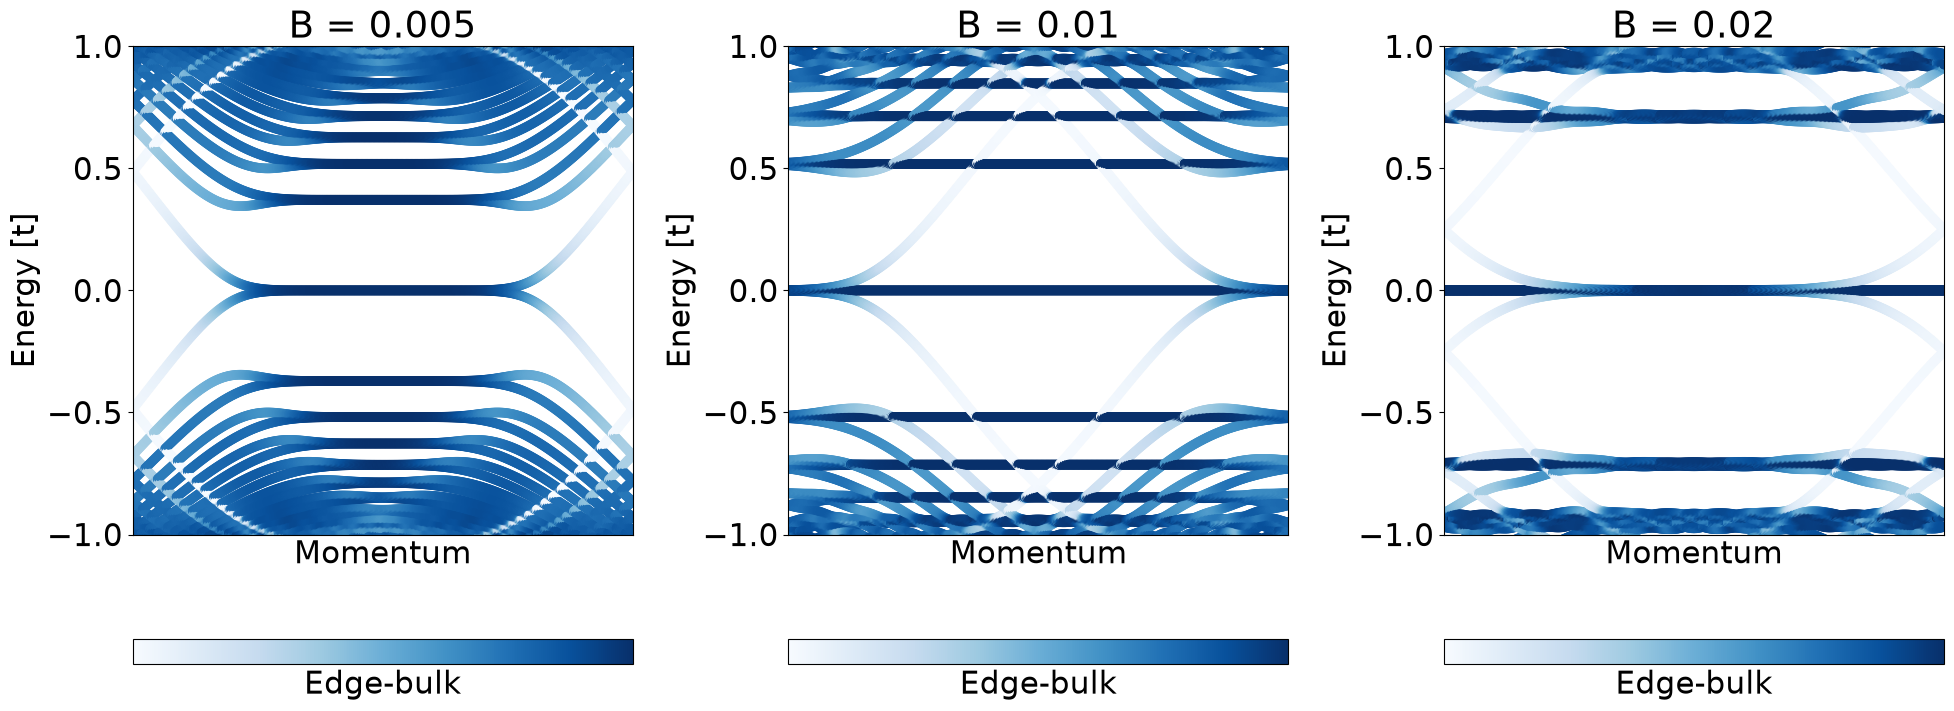

In [9]:
from pyqula import geometry
N = 30 # number of unit cells as the width
g = geometry.honeycomb_armchair_ribbon(N) # honeycomb ribbon with armchair edge, the number controls the width
Bs = [0.005,0.01,0.02] # magnetic field (measured in units of magnetic flux)

ii = 0 # counter
for B in Bs: # loop over magnetic fields
    h = g.get_hamiltonian(has_spin=False) # generate the Hamiltonian
    h.add_orbital_magnetic_field(B) # add an out-of plane magnetic field
    # plot the bands
    plt.subplot(1,len(Bs),ii+1) ; plt.title("B = "+str(B)) ; ii += 1 # create subplot and increase counter
    (k,e,c) = h.get_bands(kpath=["X","G","X"],operator="bulk") # compute band structure
    plt.scatter(k,e,c=c,cmap="Blues") ; plt.xlabel("Momentum") ; plt.ylabel("Energy [t]") ; plt.xticks([])
    plt.ylim([-1,1]) ; plt.xlim([min(k),max(k)])
    plt.colorbar(location="bottom",ticks=[],label="Edge-bulk")
plt.tight_layout()

### Quiz
- Why are there Landau levels of Dirac equation in the honeycomb lattice
- Why does the spacing between Landau levels increase with field
- Why are the Landau levels not equally spaced?
- Increase the width of the ribbon. Do the energies of the flat bands change? Explain why

## Magnetic field dependence of Dirac Landau levels (***Core***)
Let us now explicitly see how the energy of the Landau levels depends on the magnetic field

As before, every Landau level gives a peak in the density of states. Since now the levels go as $E_n\propto\mathrm{sgn}(n)\sqrt{|n|B}$, the way the peaks move when you increase $B$ is different from the square lattice, in particular the peaks close to $E=0$ separate faster than the ones at higher energies.

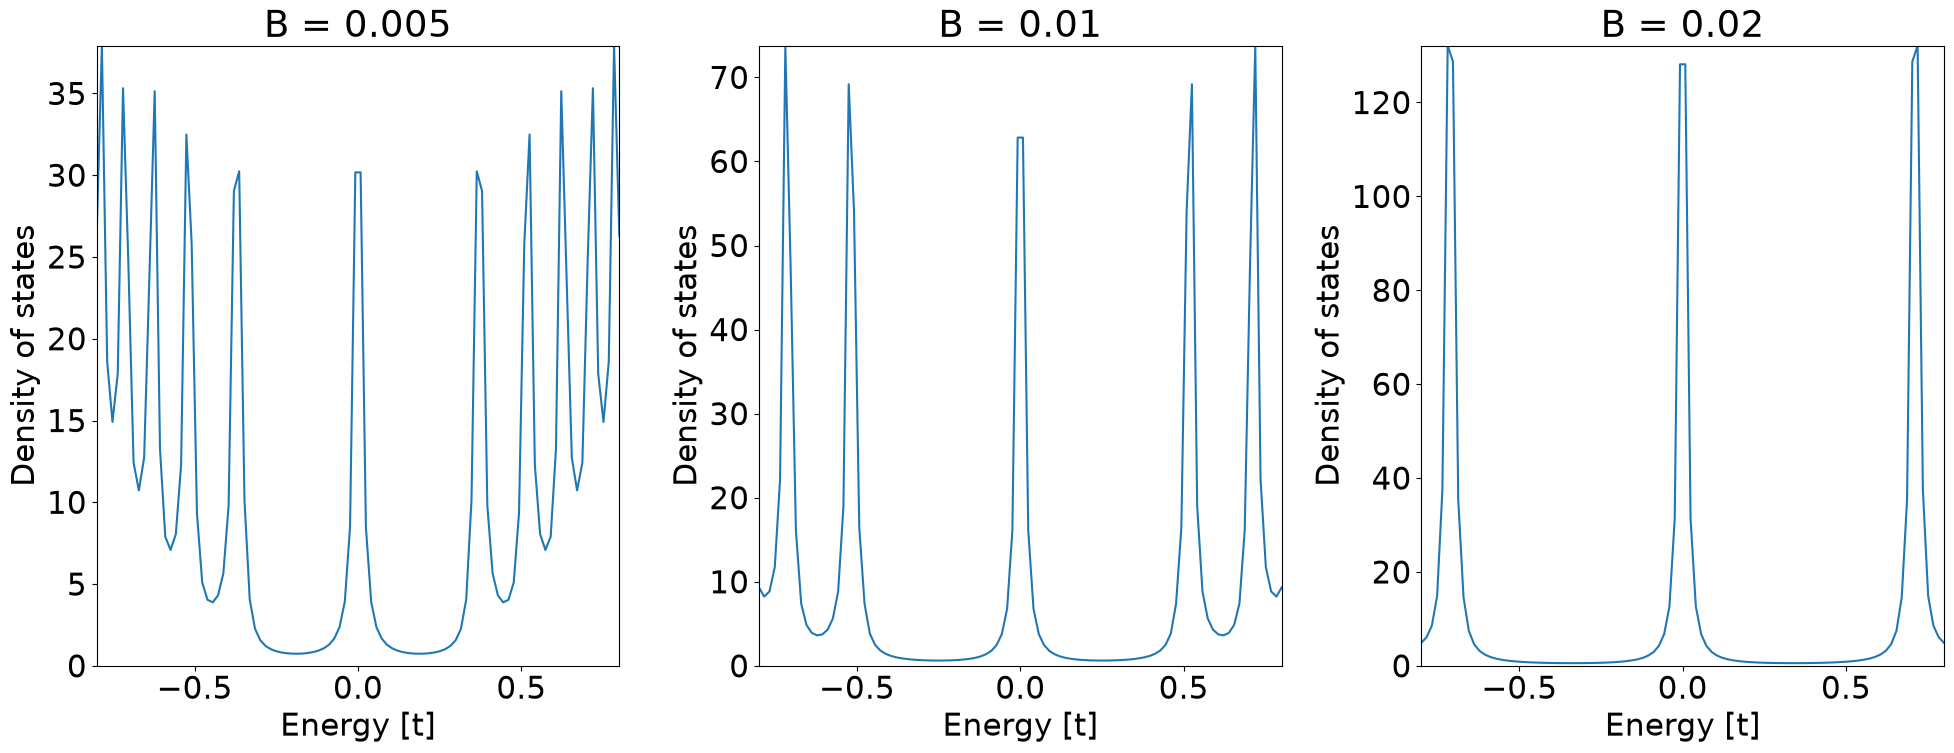

In [10]:
from pyqula import geometry
W = 40 # number of unit cells as the width
g = geometry.honeycomb_armchair_ribbon(W) # honeycomb ribbon with armchair edge, the number controls the width
Bs = [0.005,0.01,0.02] # magnetic field (measured in units of magnetic flux)

energies = np.linspace(-0.8,.8,100)

ii = 0 # counter
for B in Bs: # loop over magnetic fields
    h = g.get_hamiltonian(has_spin=False) # generate the Hamiltonian
    h.add_orbital_magnetic_field(B) # add an out-of plane magnetic field
    plt.subplot(1,len(Bs),ii+1) ; plt.title("B = "+str(B)) ; ii += 1 # create subplot and increase counter
    (e,d) = h.get_dos(operator="bulk",energies=energies,delta=1e-2,nk=400) # compute DOS projected on the bulk
    plt.plot(e,d) ; plt.ylim([0,max(d)]) ; plt.xlim([min(e),max(e)]) # plot the DOS
    plt.xlabel("Energy [t]") ; plt.ylabel("Density of states")
plt.tight_layout()

### Quiz
- Why are there peaks in the density of states?
- Increase the width $W$ of the ribbon. Do the peaks change? Explain why.

## Imaging the magnetic field dependence in the Dirac Landau levels (***Core***)
We will now see explicitly the evolution of the Dirac Landau energy levels with magnetic field

Now we plot again the density of states as a function of energy and magnetic field. The Landau fan of Dirac electrons follows $E_n(B)=\mathrm{sgn}(n)\sqrt{2|n|\hbar v_F^2 eB}$, so instead of straight lines you get curves, and the $n=0$ level stays pinned at $E=0$ for all fields. This is the way in which one distinguishes experimentally Dirac electrons from conventional ones.

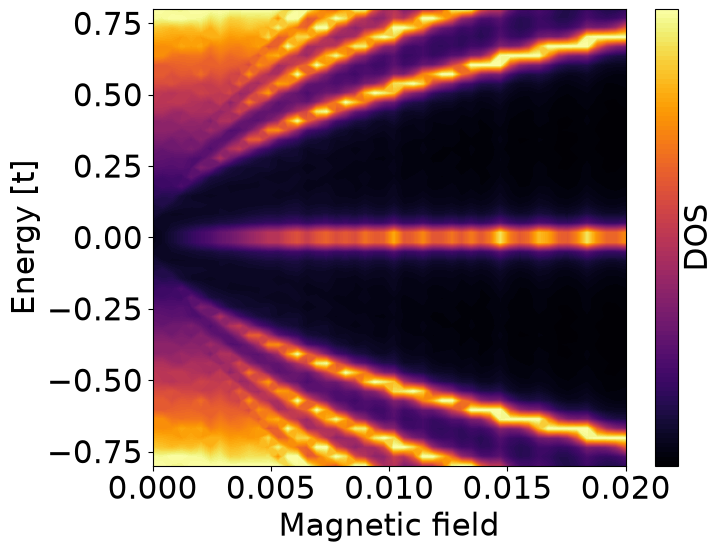

In [11]:
from pyqula import geometry
W = 30 # number of unit cells as the width
g = geometry.honeycomb_armchair_ribbon(W) # honeycomb ribbon
ngrid = 50 # grid points
Bs = np.linspace(0.0,0.02,ngrid) # magnetic field (measured in units of magnetic flux)

energies = np.linspace(-.8,.8,ngrid) # energies for the DOS

d_arr,b_arr,e_arr, = [],[],[] # storage for all he energies, magnetic fields and DOS

ii = 0 # counter
for B in Bs: # loop over magnetic fields
    h = g.get_hamiltonian(has_spin=False) # generate the Hamiltonian
    h.add_orbital_magnetic_field(B) # add an out-of plane magnetic field
    (e,d) = h.get_dos(energies=energies,delta=2e-2,nk=40) # compute DOS
    d_arr.append(d/np.max(d)) ; e_arr.append(e) ; b_arr.append(e*0. + B) # store E, B and DOS

# now make the plot    
fig = plt.figure(figsize=[8,6])
plt.contourf(Bs,energies,np.array(d_arr).T,cmap="inferno",levels=100)
plt.colorbar(label="DOS",ticks=[]) ; plt.xlabel("Magnetic field") ; plt.ylabel("Energy [t]")
plt.xlim([np.min(b_arr),np.max(b_arr)]) ; plt.ylim([np.min(e_arr),np.max(e_arr)])
plt.tight_layout()

### Quiz
- What are the peaks in the DOS?
- Increase the width $W$ of the ribbon. Do the peaks in the DOS change? Explain why.
- How does the spacing between peaks evolve with the magnetic field?
- Make the ribbon much narrower. Why does the density of states become so different?

#### In the lab
- The quantum Hall state in graphene appears even at room temperature
https://www.science.org/doi/10.1126/science.1137201

## Localization of the edge states in the quantum Hall effect in a ribbon (***Challenge***)
Let us now look at where the states are localized as function of energy

As in session 3, we compute the local density of states of the ribbon at several energies, marked in the band structure on the left. At an energy between two Landau levels the only states are the chiral edge states, so the weight is concentrated at the boundaries, whereas at the energy of a Landau level the weight spreads over the bulk. Compare each panel with the band structure at the same energy.

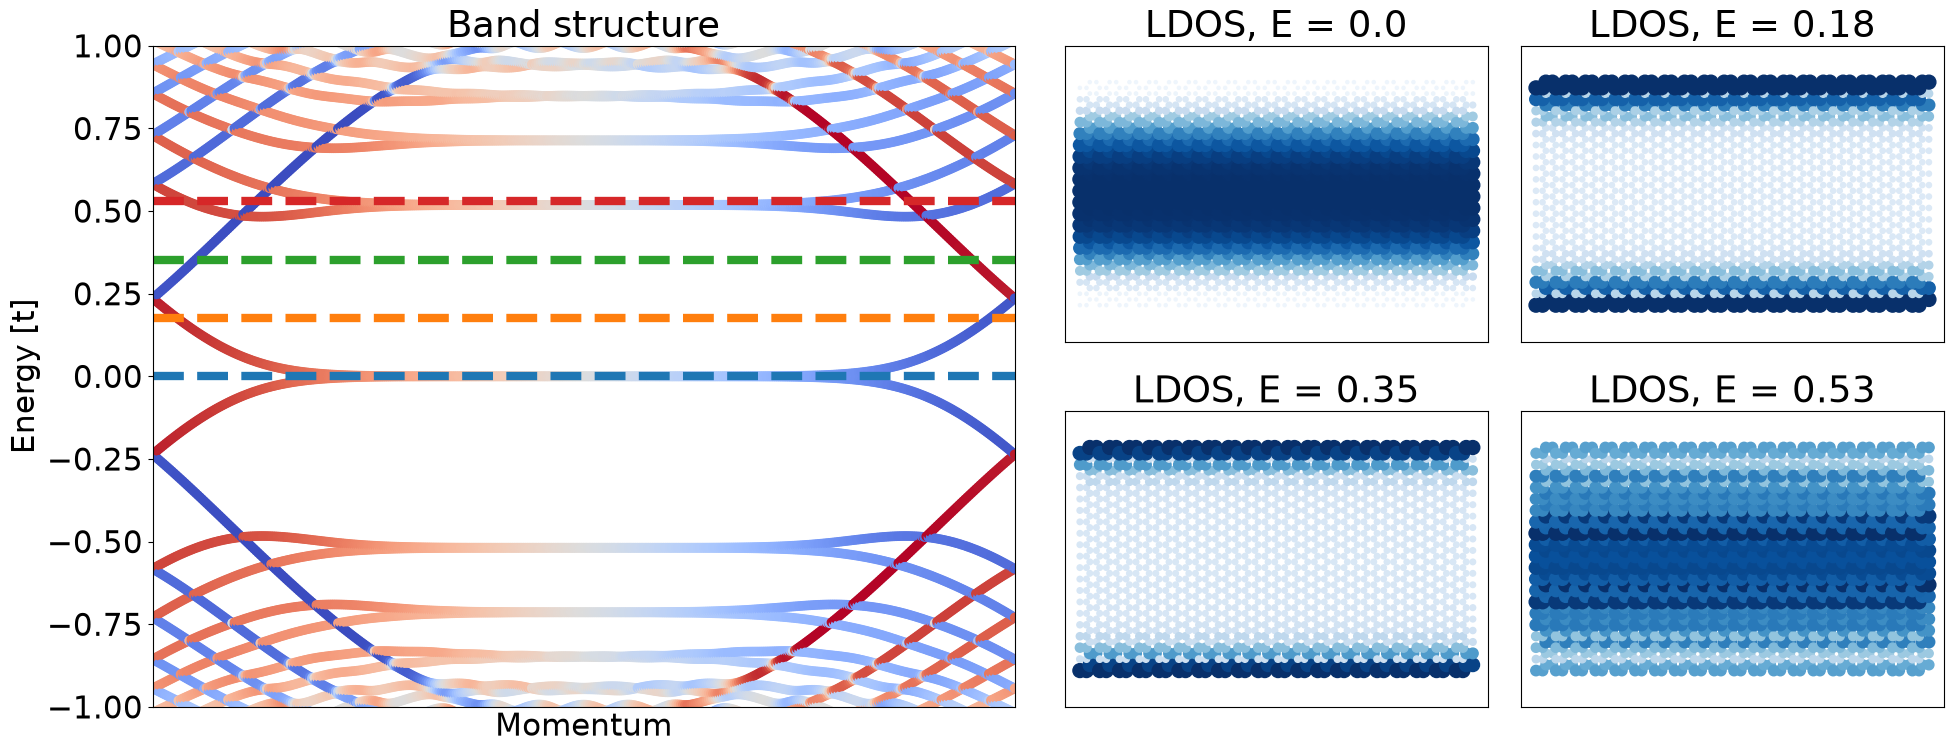

In [12]:
from pyqula import geometry
ws = np.linspace(0.,0.53,4) # energies
iis = [3,4,7,8] # indexes for the plot

g = geometry.honeycomb_armchair_ribbon(20) # honeycomb ribbon with armchair edge, the number controls the width
h = g.get_hamiltonian(has_spin=False) # generate the Hamiltonian
h.add_orbital_magnetic_field(0.01) # add an out-of plane magnetic field

ii = 0 # counter for the subplots
for w in ws:
    plt.subplot(2,4,iis[ii]) ; ii+=1
    (x,y,d) = h.get_ldos(e=w,nrep=20,delta=1e-2,nk=50) # compute local density of states
    plt.title("LDOS, E = "+str(np.round(w,2))) # set the title
    plt.scatter(x,y,c=d,s=d/np.max(d)*100,vmin=0.,cmap="Blues") ; plt.yticks([]) ; plt.xticks([]) ; plt.axis("equal")# plot
plt.tight_layout() # adjust the subplots


# plot the bands
plt.subplot(1,2,1) ; plt.title("Band structure")
(k,e,c) = h.get_bands(kpath=["X","G","X"],operator="yposition") # compute band structure
plt.scatter(k,e,c=c) ; plt.xlabel("Momentum") ; plt.ylabel("Energy [t]") ; plt.xticks([]) 
for w in ws: # plot the energies
    plt.plot([min(k),max(k)],[w,w],linewidth=6,linestyle="dashed")
plt.ylim([-1,1.]) ; plt.xlim([min(k),max(k)])

plt.tight_layout()

### Quiz
- Recompute the previous local density of states, but now with a smaller magnetic field. What happens to the edge states?
- Recompute the previous local density of states, but now with a narrower ribbon. What happens to the edge states?

## Localization of the edge states in the quantum Hall effect in an island (***Challenge***)
Let us now look at where the states are localized as function of energy in a finite island

In a finite island there is no momentum along the edge anymore, so we cannot plot a band structure, but the same logic holds locally. At an in-gap energy the local density of states follows the perimeter of the island, the edge states now go all the way around, whereas at the energy of a Landau level the weight fills the interior.

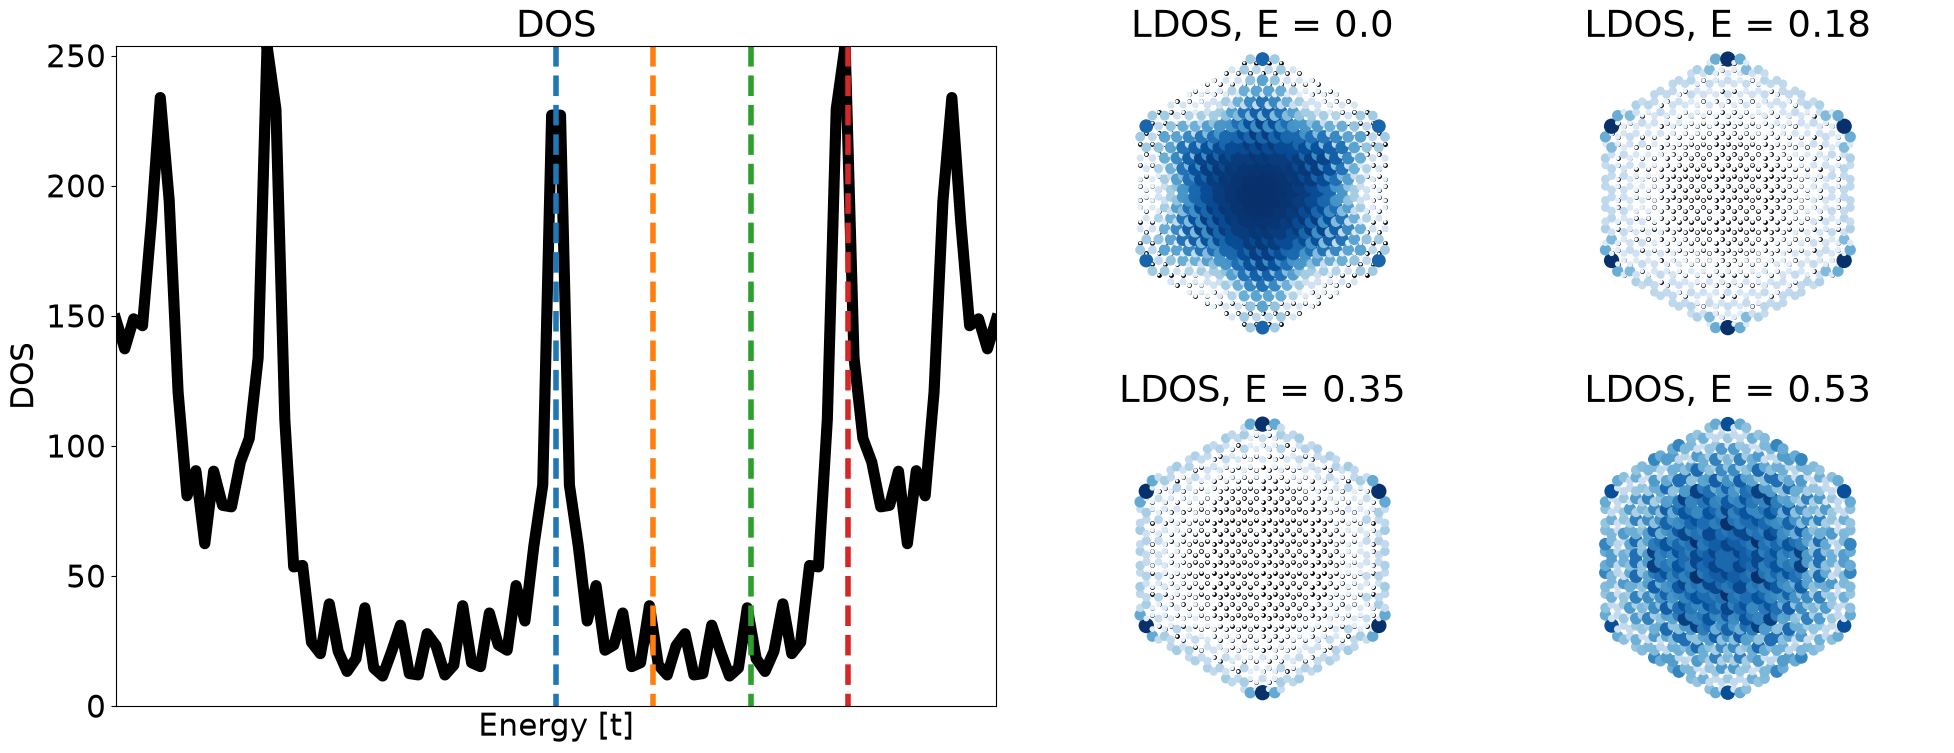

In [13]:
from pyqula import islands
W = 12 # this controls the size of the island
g = islands.get_geometry(name="honeycomb",n=W,nedges=6,rot=np.pi/6.) # get an armchair island
h = g.get_hamiltonian(has_spin=False) # generate the Hamiltonian
h.add_orbital_magnetic_field(0.01) # add an out-of plane magnetic field

ws = np.linspace(0.,0.53,4) # energies
iis = [3,4,7,8] # indexes for the plot

ii = 0 # counter for the subplots
for w in ws:
    plt.subplot(2,4,iis[ii]) ; ii+=1
    (x,y,d) = h.get_ldos(e=w,nrep=20,delta=1e-2,nk=50) # compute local density of states
    plt.title("LDOS, E = "+str(np.round(w,2))) # set the title
    plt.scatter(x,y,s=6,c="black")
    plt.scatter(x,y,c=d,s=d/np.max(d)*100,vmin=0.,cmap="Blues") ; plt.yticks([]) ; plt.xticks([]) 
    plt.axis("equal") ; plt.axis("off")


# plot the DOS
energies = np.linspace(-0.8,.8,100) # energies for DOS
plt.subplot(1,2,1) ; plt.title("DOS")
(e,d) = h.get_dos(energies=energies,delta=1e-2) # compute DOS 
plt.plot(e,d,c="black",linewidth=8) ; plt.ylabel("DOS") ; plt.xlabel("Energy [t]") ; plt.xticks([]) 
for w in ws: # plot the energies
    plt.plot([w,w],[max(d),0.],linewidth=4,linestyle="dashed") # energies of the LDOS
plt.ylim([0,max(d)]) ; plt.xlim([min(e),max(e)])

plt.tight_layout() # adjust the subplots

### Quiz
- Recompute the previous local density of states, but now with a smaller magnetic field. What happens to the edge states?
- Recompute the previous local density of states, but now with a narrower ribbon. What happens to the edge states?
- Can you understand the spectra in this geometry by looking at the one shown in the ribbon previously?

## Topological equivalence between the Quantum Hall state and a Chern insulator (***Challenge***)
Here we will show that a quantum Hall state can be adiabatically connected to a Chern insulator

The idea is very simple: we take the Hamiltonian of a quantum Hall state, $H_{QH}$, and the Hamiltonian of a Chern insulator, $H_{C}$, and we interpolate between them, $H(\nu)=\nu H_{QH}+(1-\nu)H_{C}$, computing the band structure of a ribbon along the way. If the bulk gap never closes during the interpolation, the two states have to share the same Chern number, even though one is driven by a real magnetic field and the other one by the Haldane term with zero net flux. What matters for the topology is the Chern number, not where the gap comes from.

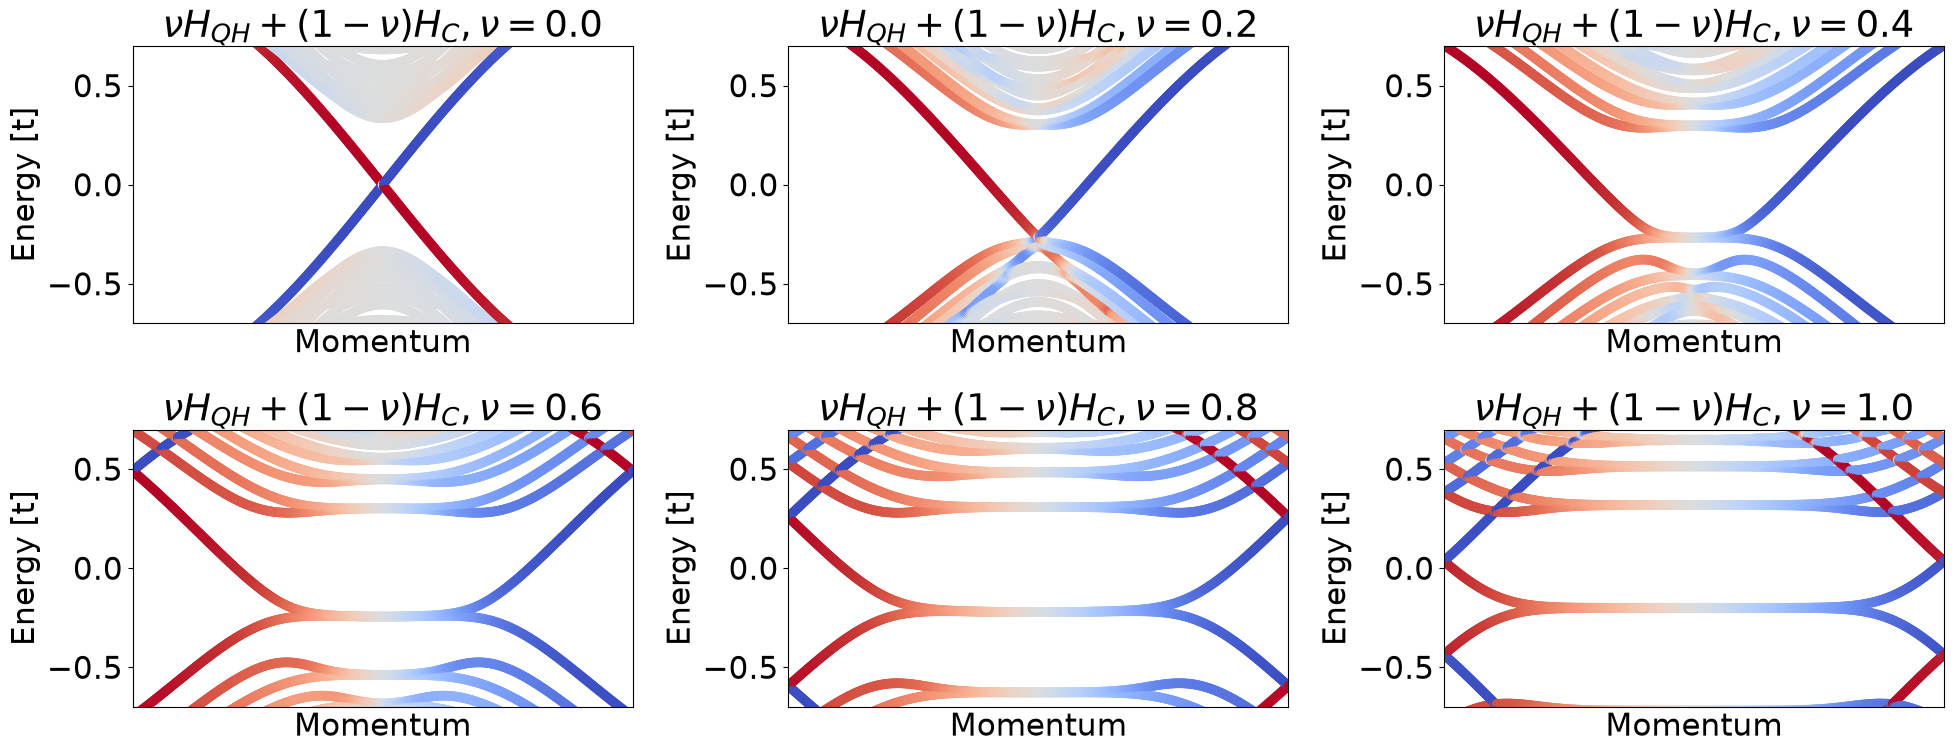

In [14]:
from pyqula import geometry
W = 20 # width of the ribbon
g = geometry.honeycomb_armchair_ribbon(W) # honeycomb ribbon with armchair edge
#g = geometry.honeycomb_zigzag_ribbon(W) # honeycomb ribbon with zigzag edge

# create a quantum Hall state
H_hall = g.get_hamiltonian(has_spin=False) # generate the Hamiltonian
H_hall.add_orbital_magnetic_field(0.01) # add an out-of plane magnetic field
H_hall.add_onsite(-0.2) # shift the chemical potential

# create a Chern insulator
H_chern = g.get_hamiltonian(has_spin=False) # generate the Hamiltonian
H_chern.add_haldane(0.07) # open a topological gap with C=1

nus = np.linspace(0.,1.,6) # interpolate between both Hamiltonians

ii = 1 # initialize
for nu in nus: # loop over interpolations
    H = H_hall*nu + H_chern*(1-nu) # interpolated Hamiltonian
    (k,e,c) = H.get_bands(kpath=["X","G","X"],operator="yposition") # compute band structure
    plt.subplot(2,len(nus)//2,ii) ; ii+=1
    plt.scatter(k,e,c=c) ; plt.xlabel("Momentum") ; plt.ylabel("Energy [t]") ; plt.xticks([])
    plt.title("$\\nu H_{QH} + (1-\\nu) H_{C}, \\nu = $"+str(np.round(nu,1)))
    plt.ylim([-0.7,0.7]) ; plt.xlim([min(k),max(k)])
plt.tight_layout()

### Quiz
- How do you know in the previous plots that the bulk gap is not closing?
- Can you follow the evolution of the edge modes from Hamiltonian to Hamiltonian
- If you make the ribbon wider $W$, does the previous phenomenology change? Explain why.
- If you make the ribbon narrower $W$, does the previous phenomenology change? Explain why.

## Topological domains in the quantum Hall state (***Challenge***)
We will now see how regions with different Chern numbers give rise to interface modes

Here we take a ribbon where the chemical potential changes sign between the upper half and the lower half. You can think that the two halves are two quantum Hall states with opposite Chern number, one with particle-like Landau levels and the other one with hole-like Landau levels. Since the Chern number jumps at the interface, there must be modes bound to that domain wall, on top of the ones at the outer edges, and the number of such modes is set by how big the jump is.

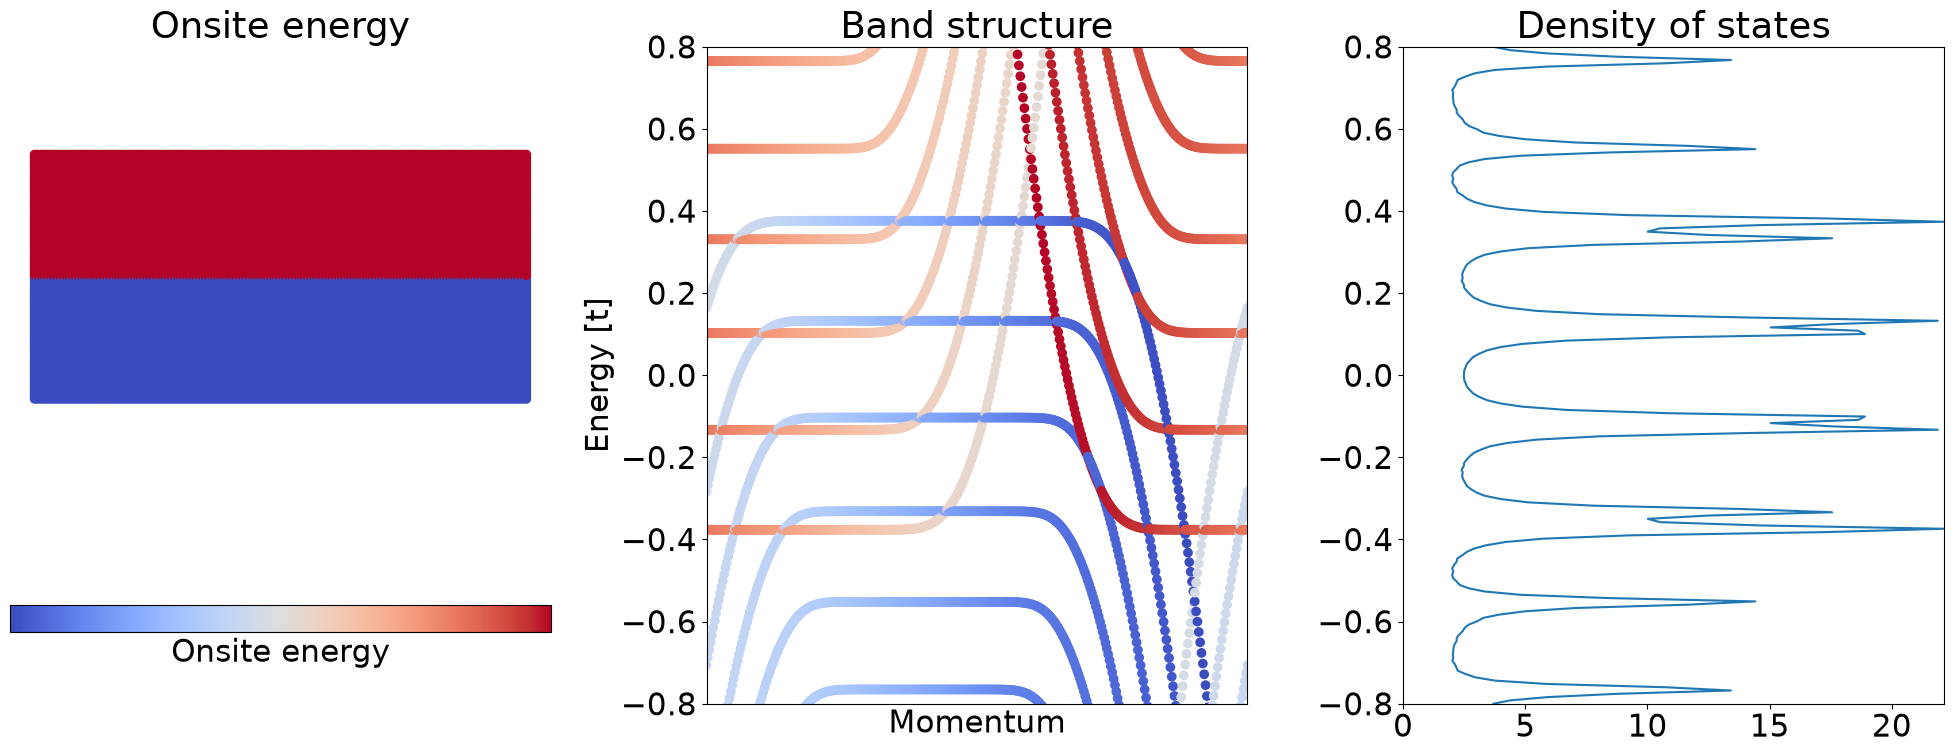

In [15]:
from pyqula import geometry
W = 80 # width
g = geometry.square_ribbon(W) # square ribbon, the number controls the width
g.center()
h = g.get_hamiltonian(has_spin=False) # generate the Hamiltonian
B = 0.02 # magnetic field (in unit flux units)
h.add_orbital_magnetic_field(B) # add an out-of plane magnetic field

mu = 3.5 # chemical potential for the parabolic bands

def mufun(r): # spatially dependent chemical potential
    if r[1]>0.: return mu # hole band in the upper part
    else: return -mu # electron band in the bottom part

h.add_onsite(mufun) # add spatially dependent chemical potential
    
# draw a ribbon
gs = g.get_supercell(2*W) 
plt.subplot(1,3,1) ; plt.title("Onsite energy")
cs = [mufun(ri) for ri in gs.r] # color according to onsite energy
plt.scatter(gs.r[:,0],gs.r[:,1],c=cs) ; plt.axis("equal") ; plt.axis("off")
plt.colorbar(location="bottom",ticks=[],label="Onsite energy")

# plot the bands
plt.subplot(1,3,2) ; plt.title("Band structure")
energies = np.linspace(-.8,.8,200) # energies for the DOS (to be used later)
(k,e,c) = h.get_bands(kpath=["G","X","G"],operator="yposition") # compute band structure
plt.scatter(k,e,c=c) ; plt.xlabel("Momentum") ; plt.ylabel("Energy [t]") ; plt.xticks([]) 
plt.ylim([min(energies),max(energies)]) ; plt.xlim([min(k),max(k)])


# now plot the DOS
plt.subplot(1,3,3) ; plt.title("Density of states")
(e,d) = h.get_dos(energies=energies,delta=1e-2,nk=400) # compute DOS
plt.plot(d,e) ; plt.xlim([0,max(d)]) ; plt.ylim([min(e),max(e)]) # plot the DOS

plt.tight_layout()

### Quiz
- Why do the edge states propagate in different directions in the two domains?
- What is the Chern number of the upper and lower part of the ribbon
- Make the ribbon wider, does the number of edge states crossing zero energy change?
- What is the relative sign of the Hall conductivity in the top with respect to the bottom?